# Example 4.4: RBF Network for Path Error Prediction
**Chapter 4 · Neural Networks for Mechanism Design**

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

## Statement
Generate 300 synthetic four-bar mechanisms and train an RBF network with:
- **K = 30** centros (muestreo aleatorio de entrenamiento)
- **σ = 0.5** (ancho de las funciones gaussianas)
- **λ = 1×10⁻⁴** (regularización de Tikhonov)

Los pesos de salida se obtienen analíticamente: **W = (ΦᵀΦ + λI)⁻¹ Φᵀy**.
Evaluate the model with MSE, RMSE and R² at 30% testing.

In [1]:
# ── Seed and synthetic data─────────────────────────────────────────
from numpy import *
import matplotlib.pyplot as plt

random.seed(7)
N_DATOS = 300;  N_CENT = 30;  SIGMA = 0.5;  LAMBDA_REG = 1e-4

a = random.uniform(0.5, 2.0, N_DATOS)
b = random.uniform(0.5, 2.0, N_DATOS)
c = random.uniform(0.5, 2.0, N_DATOS)
d = ones(N_DATOS)
theta2 = random.uniform(0, 2*pi, N_DATOS)
y = (sin(theta2) * a/d + 0.3*cos(2*theta2) * b/c + 0.1*random.randn(N_DATOS))
X = column_stack([theta2, a, b, c])

idx = random.permutation(N_DATOS)
n_tr = int(0.7 * N_DATOS)
X_tr, y_tr = X[idx[:n_tr]], y[idx[:n_tr]]
X_te, y_te = X[idx[n_tr:]], y[idx[n_tr:]]

idx_c = random.choice(n_tr, N_CENT, replace=False)
C = X_tr[idx_c]

def rbf_matrix(X_in, centers, sigma):
    K = centers.shape[0]; N = X_in.shape[0]
    Phi = zeros((N, K))
    for k in range(K):
        diff = X_in - centers[k]
        Phi[:, k] = exp(-sum(diff**2, axis=1) / (2 * sigma**2))
    return Phi

Phi_tr = rbf_matrix(X_tr, C, SIGMA)
Phi_te = rbf_matrix(X_te, C, SIGMA)

A     = Phi_tr.T @ Phi_tr + LAMBDA_REG * eye(N_CENT)
b_vec = Phi_tr.T @ y_tr
W     = linalg.solve(A, b_vec)

y_tr_pred = Phi_tr @ W
y_te_pred = Phi_te @ W
mse_tr  = mean((y_tr - y_tr_pred)**2)
mse_te  = mean((y_te - y_te_pred)**2)
rmse_te = sqrt(mse_te)
r2_te   = 1 - sum((y_te - y_te_pred)**2) / sum((y_te - mean(y_te))**2)
print(f'Red RBF — {N_CENT} centros, sigma={SIGMA}')
print(f'MSE entrenamiento: {mse_tr:.5f}')
print(f'MSE prueba:        {mse_te:.5f}')
print(f'RMSE prueba:       {rmse_te:.5f}')
print(f'R^2 prueba:        {r2_te:.4f}')



Red RBF — 30 centros, sigma=0.5
MSE entrenamiento: 0.16648
MSE prueba:        0.16920
RMSE prueba:       0.41134
R^2 prueba:        0.8307


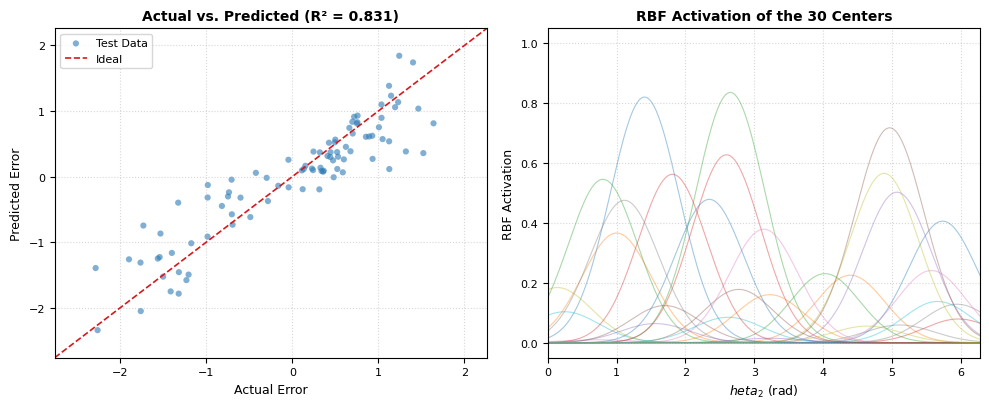

In [4]:
import os
import glob
import builtins
from numpy import *
import matplotlib.pyplot as plt

# ── Springer & Vector Quality Setup ──────────────────────────────────
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Helvetica', 'Arial', 'sans-serif']
plt.rcParams['font.family'] = 'sans-serif'

# ── Automated Output Filename ───────────────────────────────────────
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "fig4_4_rbf_trajectory_prediction"
except Exception:
    notebook_name = "fig4_4_rbf_trajectory_prediction"

# ── Plotting ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

# Subplot 1: Actual vs Predicted
ax = axes[0]
ax.scatter(y_te, y_te_pred, s=20, alpha=0.6, color='#2c7bb6', edgecolors='none', label='Test Data')

# Use builtins.min/max to prevent NumPy namespace conflicts
min_val = builtins.min(y_te.min(), y_te_pred.min())
max_val = builtins.max(y_te.max(), y_te_pred.max())
margin = 0.1 * (max_val - min_val)
lims = [min_val - margin, max_val + margin]

ax.plot(lims, lims, color='#d7191c', linestyle='--', lw=1.2, label='Ideal')
ax.set_xlim(lims)
ax.set_ylim(lims)

ax.set_xlabel('Actual Error', fontsize=9)
ax.set_ylabel('Predicted Error', fontsize=9)
ax.set_title(f'Actual vs. Predicted (R² = {r2_te:.3f})', fontsize=10, fontweight='bold')
ax.grid(True, linestyle=':', alpha=0.5)
ax.tick_params(labelsize=8)
ax.legend(fontsize=8, loc='upper left')

# Subplot 2: RBF Activations
ax2 = axes[1]
theta_plot = linspace(0, 2*pi, 200)
# Use ones(200) instead of full() to avoid type conversion warnings
X_plot = column_stack([theta_plot, ones(200), ones(200), ones(200)])
Phi_plot = rbf_matrix(X_plot, C, SIGMA)

for k in range(N_CENT):
    ax2.plot(theta_plot, Phi_plot[:, k], alpha=0.4, lw=0.8)

ax2.set_xlim([0, 2*pi])
ax2.set_ylim([-0.05, 1.05])
ax2.set_xlabel('$\theta_2$ (rad)', fontsize=9)
ax2.set_ylabel('RBF Activation', fontsize=9)
ax2.set_title(f'RBF Activation of the {N_CENT} Centers', fontsize=10, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.tick_params(labelsize=8)

plt.tight_layout()

# Double Export System
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()